# Prévoir les crues en France : cette rivière va-t-elle déborder dans les 3 prochains jours ?

Chaque année, les inondations sont le premier risque naturel en France (environ 1 commune sur 4 est exposée).
Le réseau Vigicrues surveille les grands cours d'eau, mais beaucoup de petites rivières réagissent en quelques heures
et ne sont pas suivies de près.

**Question :** à partir de la pluie, de la température et du débit observés aujourd'hui, peut-on prédire
qu'une rivière dépassera son **niveau de crue** dans les 3 prochains jours ? Et que gagne-t-on à ajouter une **prévision météo** ?

**Données :** 19 bassins versants français, de la Bretagne à la Corse, observés chaque jour de 1999 à 2018
(extrait de la base **CAMELS-FR** de l'INRAE : pluie et température Météo-France SAFRAN, débits SCHAPI / Hydroportail).

**Plan**
1. Les données et la carte des bassins
2. Qu'est-ce qu'une crue ? (définition, exemples, saisons)
3. Les variables explicatives et le découpage dans le temps
4. Quatre modèles, trois scénarios de prévision météo
5. Évaluation par épisode : combien de crues sont annoncées à l'avance ?
6. Deux crues réelles : le Loing en juin 2016 et la Seine en janvier 2018
7. Qu'est-ce que le modèle regarde ?
8. Le modèle marche-t-il sur une rivière qu'il n'a jamais vue ?
9. Conclusion et limites

In [1]:
import sys, warnings
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

from src.donnees import charger_series, charger_stations, seuils_de_crue, periode, episodes_de_crue
from src.variables import construire_table, prevision_bruitee, SANS_PREVISION, AVEC_PREVISION, FAMILLES, HORIZON
from src.modeles import (CIBLE, RegleNaive, regression_logistique, foret_aleatoire, xgboost,
                         entrainer_xgboost, proba, choisir_seuil_alerte)
from src.evaluation import scores, evaluer_episodes, importance_par_famille
from src.carte import fond_de_carte
from src import graphiques as G

G.appliquer_style()
FIG, RES = RACINE / "figures", RACINE / "resultats"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)

## 1. Les données

Chaque ligne donne, pour une station et un jour : la pluie tombée sur le bassin (mm), la température moyenne (°C),
l'évapotranspiration potentielle (mm, l'eau que l'atmosphère « pompe ») et le débit de la rivière.
Le débit est exprimé en **mm/jour** (volume écoulé divisé par la surface du bassin) : on peut ainsi comparer
directement la pluie qui tombe et l'eau qui sort.

In [2]:
df = charger_series()
stations = charger_stations()
print(f"{df['code'].nunique()} stations, {len(df):,} jours-stations, du {df['date'].min():%d/%m/%Y} au {df['date'].max():%d/%m/%Y}")
print(f"Débits manquants : {df['debit_mm'].isna().mean():.1%}")
df.head()

19 stations, 138,795 jours-stations, du 01/01/1999 au 31/12/2018
Débits manquants : 0.9%


,code,date,pluie_mm,temp_c,etp_mm,debit_mm
0,A273011002,1999-01-01,0.0,-0.1,0.2,2.109
1,A273011002,1999-01-02,8.7,4.4,0.3,1.990
2,A273011002,1999-01-03,4.1,4.4,0.4,2.445
3,A273011002,1999-01-04,2.2,8.1,0.5,2.426
4,A273011002,1999-01-05,0.0,8.5,0.5,2.314


In [3]:
seuils = seuils_de_crue(df)
df["seuil_crue"] = df["code"].map(seuils)
nom = stations.set_index("code")["nom"]
# décalage des étiquettes sur les cartes pour éviter les chevauchements
DECALAGE = {"H010002001": (6, -13), "X045401001": (-8, -14), "K265401001": (-8, 6), "A605102001": (7, -3)}
court = nom.str.replace(r"^(La |Le |L')", "", regex=True).str.split(" à | au ").str[0]   # « Meuse », « Loing »...

jours_crue = (df["debit_mm"] > df["seuil_crue"]).groupby(df["code"]).sum()
resume = stations.set_index("code")[["nom", "surface_km2", "alt_med"]].assign(
    seuil_crue_mm=seuils.round(2), jours_de_crue=jours_crue,
    jours_par_an=(jours_crue / 20).round(1))
resume

,nom,surface_km2,alt_med,seuil_crue_mm,jours_de_crue,jours_par_an
code,,,,,,
A273011002,La Bruche à Russ,224.040,603,16.54,23,1.2
A605102001,La Meurthe à Saint-Dié-des-Vosges,370.660,589,12.51,22,1.1
B222001001,La Meuse à Saint-Mihiel,2543.240,351,8.68,25,1.2
E540031001,La Canche à Brimeux,917.250,116,2.43,114,5.7
E645651001,La Nièvre à l'Étoile,270.420,121,0.98,392,19.6
F439000101,Le Loing à Épisy,3916.710,137,2.45,45,2.2
H010002001,La Seine à Plaines-Saint-Lange,686.000,352,6.45,57,2.8
H120101001,L'Aube à Bar-sur-Aube,1297.800,316,5.96,92,4.6
H622101001,L'Aisne à Givry,2887.550,183,5.48,43,2.2


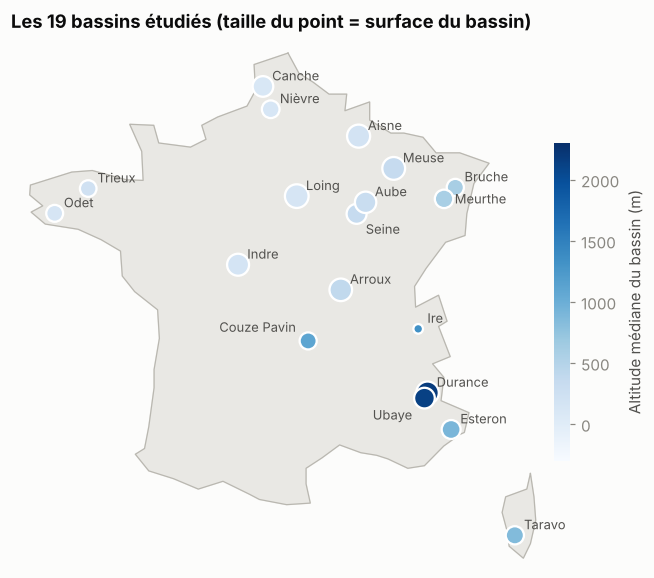

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
fond_de_carte(ax)
st = stations.set_index("code")
taille = 30 + 220 * (np.log10(st["surface_km2"]) - 1.3) / 2.4
points = ax.scatter(st["lon"], st["lat"], s=taille, c=st["alt_med"], cmap="Blues", vmin=-300, vmax=2300,
                    edgecolor="white", linewidth=1.5, zorder=3)
for code_st, r in st.iterrows():
    dx, dy = DECALAGE.get(code_st, (6, 4))
    ax.annotate(court[code_st], (r["lon"], r["lat"]), xytext=(dx, dy), textcoords="offset points",
                ha="right" if dx < 0 else "left", fontsize=8.5, color=G.ENCRE_2, zorder=4)
cb = fig.colorbar(points, ax=ax, shrink=0.5, pad=0.01, ticks=[0, 500, 1000, 1500, 2000])
cb.set_label("Altitude médiane du bassin (m)")
cb.outline.set_visible(False)
ax.set_title("Les 19 bassins étudiés (taille du point = surface du bassin)")
fig.savefig(FIG / "01_carte_bassins.png")
plt.show()

La diversité est voulue : petites rivières bretonnes à réaction rapide (Odet, Trieux), grands bassins de plaine
(Meuse, Loing, Aisne), rivières de montagne nourries par la fonte des neiges (Durance, Ubaye) et torrents
méditerranéens (Esteron, Taravo en Corse). Un bon modèle doit fonctionner partout.

## 2. Qu'est-ce qu'une crue ?

On retient une définition simple et reconnue en hydrologie : une rivière est **en crue** quand son débit
journalier dépasse la **crue biennale**, le débit atteint en moyenne une année sur deux. C'est l'ordre de grandeur
du débordement hors du lit mineur. Le seuil est calculé pour chaque station sur la période 1999-2010
uniquement (la période d'apprentissage), pour ne rien emprunter au futur.

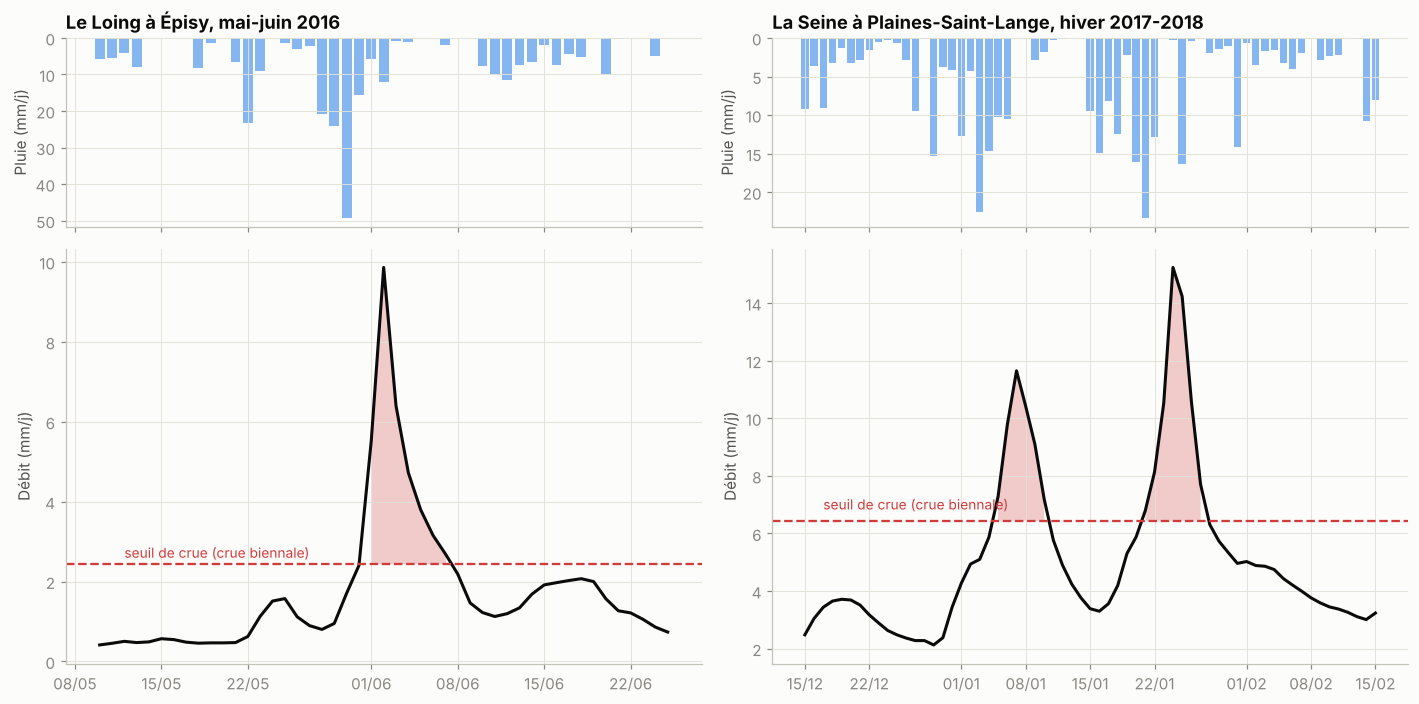

In [5]:
def hydrogramme(code_st, debut, fin, ax_p, ax_q, titre):
    g = df[(df["code"] == code_st) & (df["date"].between(debut, fin))]
    ax_p.bar(g["date"], g["pluie_mm"], color=G.PLUIE, width=0.8)
    ax_p.set_ylabel("Pluie (mm/j)")
    ax_p.invert_yaxis()
    ax_p.set_title(titre)
    ax_q.plot(g["date"], g["debit_mm"], color=G.ENCRE)
    ax_q.axhline(seuils[code_st], color=G.CRUE, lw=1.5, ls="--")
    ax_q.fill_between(g["date"], seuils[code_st], g["debit_mm"], where=g["debit_mm"] > seuils[code_st],
                      color=G.CRUE, alpha=0.25, lw=0)
    ax_q.text(g["date"].iloc[2], seuils[code_st] * 1.06, "seuil de crue (crue biennale)", color=G.CRUE, fontsize=9)
    ax_q.set_ylabel("Débit (mm/j)")
    ax_q.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))

fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex="col", gridspec_kw={"height_ratios": [1, 2.2]})
hydrogramme("F439000101", "2016-05-10", "2016-06-25", axes[0, 0], axes[1, 0], "Le Loing à Épisy, mai-juin 2016")
hydrogramme("H010002001", "2017-12-15", "2018-02-15", axes[0, 1], axes[1, 1], "La Seine à Plaines-Saint-Lange, hiver 2017-2018")
fig.tight_layout()
fig.savefig(FIG / "02_exemples_crues.png")
plt.show()

Deux mécanismes très différents :
- **Loing, juin 2016** : quatre jours de pluie exceptionnelle (plus de 100 mm cumulés) sur des sols déjà gorgés d'eau.
  Le débit monte à **4 fois** le seuil de crue : c'est la crue historique de Nemours et de Montargis.
- **Seine amont, janvier 2018** : une succession de perturbations sur plusieurs semaines. Chaque pluie fait monter
  un peu plus une rivière déjà haute : la mémoire du bassin compte autant que la pluie du jour.

Les crues ne tombent pas non plus à la même saison selon les régions :

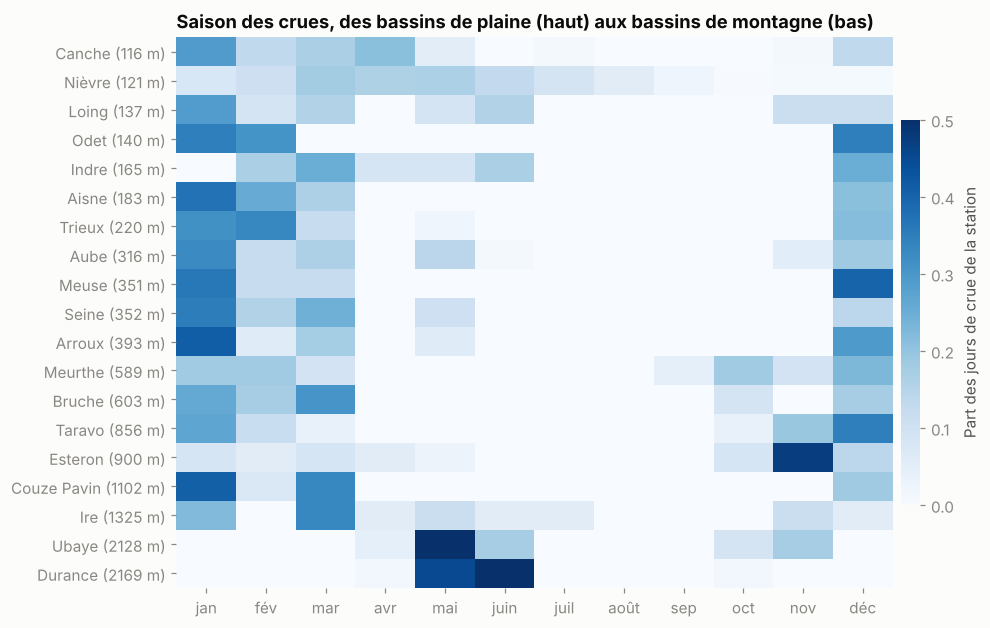

In [6]:
d = df.dropna(subset=["debit_mm"]).copy()
d["mois"] = d["date"].dt.month
d["en_crue"] = d["debit_mm"] > d["seuil_crue"]
saison = d.groupby(["code", "mois"])["en_crue"].sum().unstack(fill_value=0)
saison = saison.div(saison.sum(axis=1), axis=0)              # part des jours de crue de chaque station par mois
ordre = stations.sort_values("alt_med")["code"]
saison = saison.loc[ordre]

fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(saison.to_numpy(), cmap="Blues", aspect="auto", vmin=0, vmax=0.5)
ax.set_xticks(range(12), ["jan", "fév", "mar", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"])
ax.set_yticks(range(len(saison)), [f"{court[c]} ({stations.set_index('code').loc[c, 'alt_med']:.0f} m)" for c in saison.index])
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.01)
cb.set_label("Part des jours de crue de la station")
cb.outline.set_visible(False)
ax.set_title("Saison des crues, des bassins de plaine (haut) aux bassins de montagne (bas)")
fig.savefig(FIG / "03_saisons_crues.png")
plt.show()

En plaine, les crues arrivent en **hiver** (sols saturés, peu d'évaporation). En montagne (Durance, Ubaye),
elles arrivent en **mai-juin avec la fonte des neiges**. En Méditerranée (Esteron, Taravo), ce sont les **pluies
d'automne**. Le modèle devra donc connaître la saison, la neige et l'état des sols, pas seulement la pluie.

## 3. Variables explicatives et cible

Pour chaque station et chaque jour J, on calcule **uniquement avec l'information disponible le soir de J** :

| Famille | Variables | Pourquoi |
|---|---|---|
| Pluie passée | cumuls sur 1, 3, 7, 14 et 30 jours, maximum sur 3 jours, indice de pluie antérieure | ce qui est déjà tombé |
| Humidité des sols | bilan pluie moins évapotranspiration sur 30 et 90 jours | un sol saturé ne boit plus |
| Neige et température | stock de neige et fonte (petit modèle degré-jour), température | crues de printemps en montagne |
| Débit actuel | débit divisé par le seuil, variations sur 1 et 3 jours, max sur 7 jours, moyenne sur 30 jours | la rivière est-elle déjà haute et en train de monter ? |
| Saison | jour de l'année (sinus et cosinus) | cycle annuel |
| Bassin | surface, altitude médiane, dénivelé | un petit bassin pentu réagit plus vite |
| **Pluie prévue** | cumul et maximum de pluie, température moyenne de J+1 à J+3 | ce qu'annonce la météo |

Diviser le débit par le seuil de crue rend toutes les rivières comparables : 1 veut dire « au niveau de crue »,
que l'on parle d'un torrent corse ou de la Meuse. Un seul modèle peut alors apprendre sur les 19 bassins à la fois.

**Cible :** `crue_a_venir = 1` si le débit dépasse le seuil au moins un jour entre J+1 et J+3.

**Découpage chronologique** : apprentissage 1999-2010, validation 2011-2014 (réglages et seuil d'alerte), test 2015-2018
(jamais touché avant l'évaluation finale). Mélanger les jours au hasard serait une erreur : deux jours consécutifs
se ressemblent tellement que le modèle « tricherait ».

In [7]:
table = construire_table(df, stations, seuils)
table["periode"] = periode(table["date"])
apercu = table.groupby("periode")[CIBLE].agg(lignes="size", jours_crue_a_venir="sum", taux="mean")
apercu.loc[["entrainement", "validation", "test"]]

,lignes,jours_crue_a_venir,taux
periode,,,
entrainement,80867,1155.0,0.014
validation,27448,293.0,0.011
test,27453,260.0,0.009


L'événement est **rare** : à peine 1 % des jours. Un modèle qui dirait toujours « pas de crue » aurait 99 %
de bonnes réponses et ne servirait à rien. On utilise donc des mesures adaptées :

- **PR-AUC** (aire sous la courbe précision-rappel) : la mesure principale. Un tirage au hasard vaut environ 0,01.
- **POD** (probabilité de détection) : part des jours de crue qui avaient été annoncés.
- **FAR** (taux de fausses alertes) : part des alertes non suivies d'une crue.
- **CSI** (indice de succès critique) : le score de référence des prévisionnistes, qui pénalise à la fois les crues ratées et les fausses alertes.

Le seuil d'alerte (probabilité à partir de laquelle on alerte) est choisi sur la validation en maximisant le
F2-score : rater une crue est jugé plus grave qu'une fausse alerte.

### Trois scénarios météo

1. **Sans prévision** : le modèle ne connaît que le passé.
2. **Prévision réaliste** : on donne la pluie des 3 jours suivants, dégradée par une erreur aléatoire forte
   (souvent fausse de 50 %), pour imiter une vraie prévision de Météo-France.
3. **Prévision parfaite** : la pluie réellement tombée. Inatteignable, mais c'est le plafond de ce qu'on peut espérer.

In [8]:
tables = {
    "Sans prévision météo": (table, SANS_PREVISION),
    "Prévision réaliste": (prevision_bruitee(table, erreur=0.6, graine=1), AVEC_PREVISION),
    "Prévision parfaite": (table, AVEC_PREVISION),
}

def decouper(t):
    return [t[t["periode"] == p] for p in ("entrainement", "validation", "test")]

resultats, modeles, predictions = [], {}, {}
for scenario, (t, cols) in tables.items():
    tr, va, te = decouper(t)
    candidats = {"Règle naïve": RegleNaive(), "Régression logistique": regression_logistique(),
                 "Forêt aléatoire": foret_aleatoire()}
    for nom_m, m in candidats.items():
        m.fit(tr[cols], tr[CIBLE])
    candidats["XGBoost"] = entrainer_xgboost(tr[cols], tr[CIBLE], va[cols], va[CIBLE])
    for nom_m, m in candidats.items():
        seuil = choisir_seuil_alerte(va[CIBLE], proba(m, va[cols]))
        p_test = proba(m, te[cols])
        resultats.append({"Scénario": scenario, "Modèle": nom_m, "Seuil d'alerte": seuil,
                          **scores(te[CIBLE], p_test, seuil)})
        modeles[(scenario, nom_m)] = (m, seuil)
        predictions[(scenario, nom_m)] = p_test
    print(f"{scenario} : terminé")

res = pd.DataFrame(resultats)
res.to_csv(RES / "scores_test.csv", index=False, float_format="%.3f")
res.set_index(["Scénario", "Modèle"])

Sans prévision météo : terminé


Prévision réaliste : terminé


Prévision parfaite : terminé


Seuil d'alerte  PR-AUC  ROC-AUC  \
Scénario             Modèle                                                   
Sans prévision météo Règle naïve                      0.79   0.318    0.913   
                     Régression logistique            0.11   0.437    0.944   
                     Forêt aléatoire                  0.11   0.513    0.961   
                     XGBoost                          0.16   0.537    0.969   
Prévision réaliste   Règle naïve                      0.79   0.318    0.913   
                     Régression logistique            0.11   0.488    0.968   
                     Forêt aléatoire                  0.10   0.540    0.985   
                     XGBoost                          0.09   0.602    0.986   
Prévision parfaite   Règle naïve                      0.79   0.318    0.913   
                     Régression logistique            0.10   0.591    0.984   
                     Forêt aléatoire                  0.13   0.608    0.990   
                     XGBoost                          0.10   0.676    0.992   

                                            Brier    POD    FAR    CSI  
Scénario             Modèle                                             
Sans prévision météo Règle naïve            0.072  0.535  0.724  0.223  
                     Régression logistique  0.007  0.623  0.720  0.239  
                     Forêt aléatoire        0.006  0.654  0.662  0.287  
                     XGBoost                0.006  0.542  0.542  0.330  
Prévision réaliste   Règle naïve            0.072  0.535  0.724  0.223  
                     Régression logistique  0.007  0.646  0.697  0.260  
                     Forêt aléatoire        0.006  0.781  0.668  0.304  
                     XGBoost                0.006  0.708  0.605  0.339  
Prévision parfaite   Règle naïve            0.072  0.535  0.724  0.223  
                     Régression logistique  0.006  0.769  0.660  0.308  
                     Forêt aléatoire        0.006  0.777  0.587  0.369  
                     XGBoost                0.005  0.769  0.541  0.403

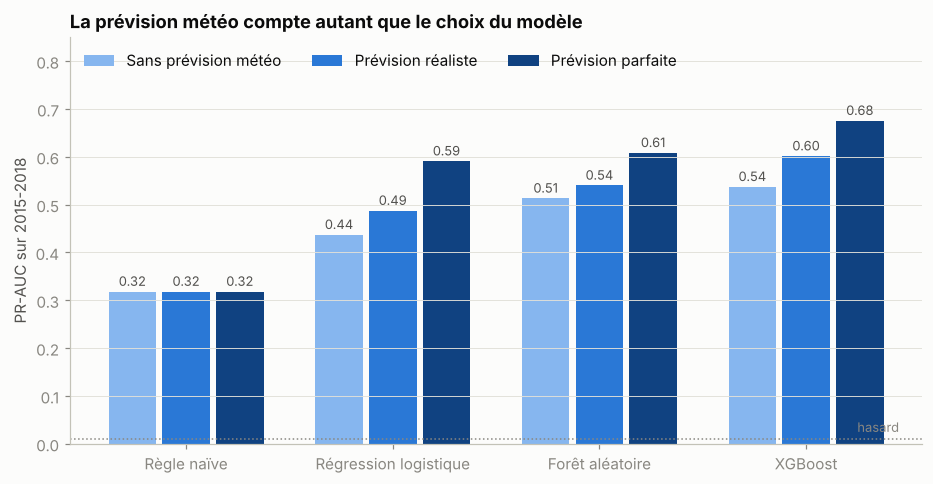

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
noms_modeles = list(G.COULEURS_MODELES)
largeur = 0.26
for i, (scenario, couleur) in enumerate(G.COULEURS_SCENARIOS.items()):
    valeurs = res[res["Scénario"] == scenario].set_index("Modèle").loc[noms_modeles, "PR-AUC"]
    x = np.arange(len(noms_modeles)) + (i - 1) * largeur
    barres = ax.bar(x, valeurs, width=largeur - 0.03, color=couleur, label=scenario)
    for xi, v in zip(x, valeurs):
        ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", fontsize=8.5, color=G.ENCRE_2)
ax.axhline(table.loc[table["periode"] == "test", CIBLE].mean(), color=G.GRIS, lw=1, ls=":")
ax.text(3.45, 0.025, "hasard", color=G.GRIS, fontsize=8.5, ha="right")
ax.set_xticks(range(len(noms_modeles)), noms_modeles)
ax.set_ylabel("PR-AUC sur 2015-2018")
ax.set_ylim(0, 0.85)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3)
ax.set_title("La prévision météo compte autant que le choix du modèle")
fig.savefig(FIG / "04_comparaison_modeles.png")
plt.show()

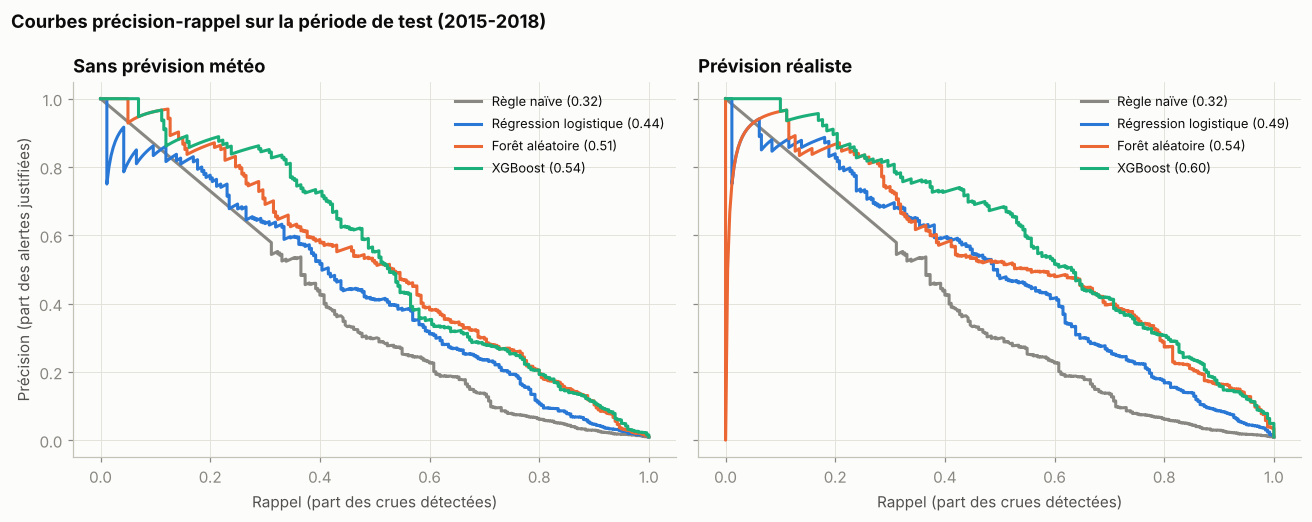

In [10]:
from sklearn.metrics import precision_recall_curve

y_test = table.loc[table["periode"] == "test", CIBLE].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, scenario in zip(axes, ["Sans prévision météo", "Prévision réaliste"]):
    for nom_m, couleur in G.COULEURS_MODELES.items():
        prec, rap, _ = precision_recall_curve(y_test, predictions[(scenario, nom_m)])
        pr_auc = res.set_index(["Scénario", "Modèle"]).loc[(scenario, nom_m), "PR-AUC"]
        ax.plot(rap, prec, color=couleur, label=f"{nom_m} ({pr_auc:.2f})")
    ax.set_xlabel("Rappel (part des crues détectées)")
    ax.set_title(scenario)
    ax.legend(loc="upper right", fontsize=8.5)
axes[0].set_ylabel("Précision (part des alertes justifiées)")
fig.suptitle("Courbes précision-rappel sur la période de test (2015-2018)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "05_courbes_precision_rappel.png")
plt.show()

**Lecture :**
- La **règle naïve** (« plus la rivière est haute, plus le risque est grand ») fait déjà bien mieux que le hasard :
  une rivière haute a de bonnes chances de le rester. Mais elle ne voit pas venir les crues qui démarrent d'un niveau normal.
- Les modèles d'apprentissage combinent pluie, sols, neige et saison et font nettement mieux.
  **XGBoost** est le meilleur dans tous les scénarios, suivi de la forêt aléatoire.
- Ajouter la **prévision météo** améliore tous les modèles, même quand cette prévision est très imparfaite.
  Pour un système d'alerte, l'information en entrée compte autant que l'algorithme.

## 5. Évaluation par épisode

Un service de secours ne raisonne pas en « jours » mais en **épisodes** : la crue a-t-elle été annoncée avant
qu'elle n'arrive, et avec combien de jours d'avance ? On regarde, pour chaque épisode de la période de test,
si une alerte a été lancée entre J-3 et la veille du premier jour de crue.

In [11]:
lignes, episodes = [], {}
for scenario, (t, cols) in tables.items():
    te = t[t["periode"] == "test"]
    m, seuil = modeles[(scenario, "XGBoost")]
    ep = evaluer_episodes(te, predictions[(scenario, "XGBoost")], seuil, horizon=HORIZON)
    episodes[scenario] = ep
    alerte = predictions[(scenario, "XGBoost")] >= seuil
    lignes.append({"Scénario": scenario, "Épisodes de crue": len(ep),
                   "Annoncés à l'avance": ep["anticipe"].mean(),
                   "Avance moyenne (jours)": ep.loc[ep["anticipe"], "avance_j"].mean(),
                   "Alertes par station et par an": alerte.sum() / te["code"].nunique() / 4})
par_episode = pd.DataFrame(lignes).set_index("Scénario")
par_episode.to_csv(RES / "evaluation_episodes.csv", float_format="%.3f")
par_episode

,Épisodes de crue,Annoncés à l'avance,Avance moyenne (jours),Alertes par station et par an
Scénario,,,,
Sans prévision météo,61,0.557,2.029,4.053
Prévision réaliste,61,0.787,2.438,6.132
Prévision parfaite,61,0.836,2.647,5.737


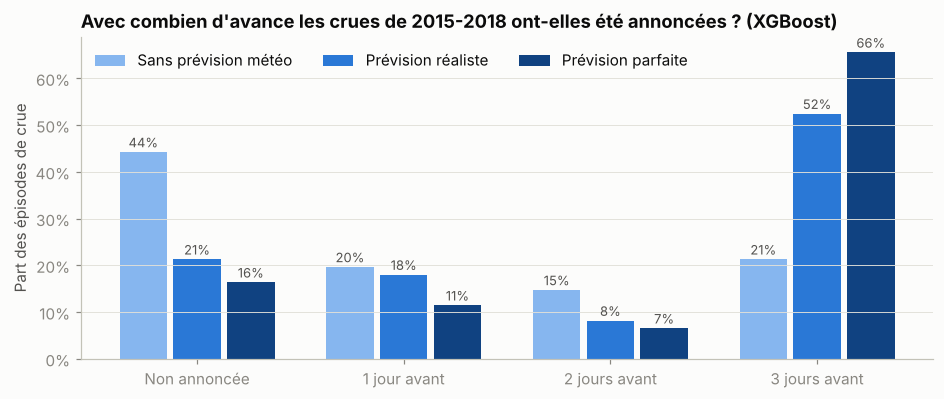

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.8))
categories = ["Non annoncée", "1 jour avant", "2 jours avant", "3 jours avant"]
largeur = 0.26
for i, (scenario, couleur) in enumerate(G.COULEURS_SCENARIOS.items()):
    ep = episodes[scenario]
    parts = [(ep["avance_j"] == k).mean() for k in range(4)]
    x = np.arange(4) + (i - 1) * largeur
    ax.bar(x, parts, width=largeur - 0.03, color=couleur, label=scenario)
    for xi, v in zip(x, parts):
        ax.text(xi, v + 0.01, f"{v:.0%}", ha="center", fontsize=8.5, color=G.ENCRE_2)
ax.set_xticks(range(4), categories)
ax.set_ylabel("Part des épisodes de crue")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3)
ax.set_title("Avec combien d'avance les crues de 2015-2018 ont-elles été annoncées ? (XGBoost)")
fig.savefig(FIG / "06_anticipation_episodes.png")
plt.show()

## 6. Deux crues réelles vues par le modèle

On trace la probabilité de crue dans les 3 jours calculée chaque soir par XGBoost (prévision réaliste),
avec le seuil d'alerte choisi sur la validation. Rappel : ces années n'ont jamais été vues pendant l'apprentissage.

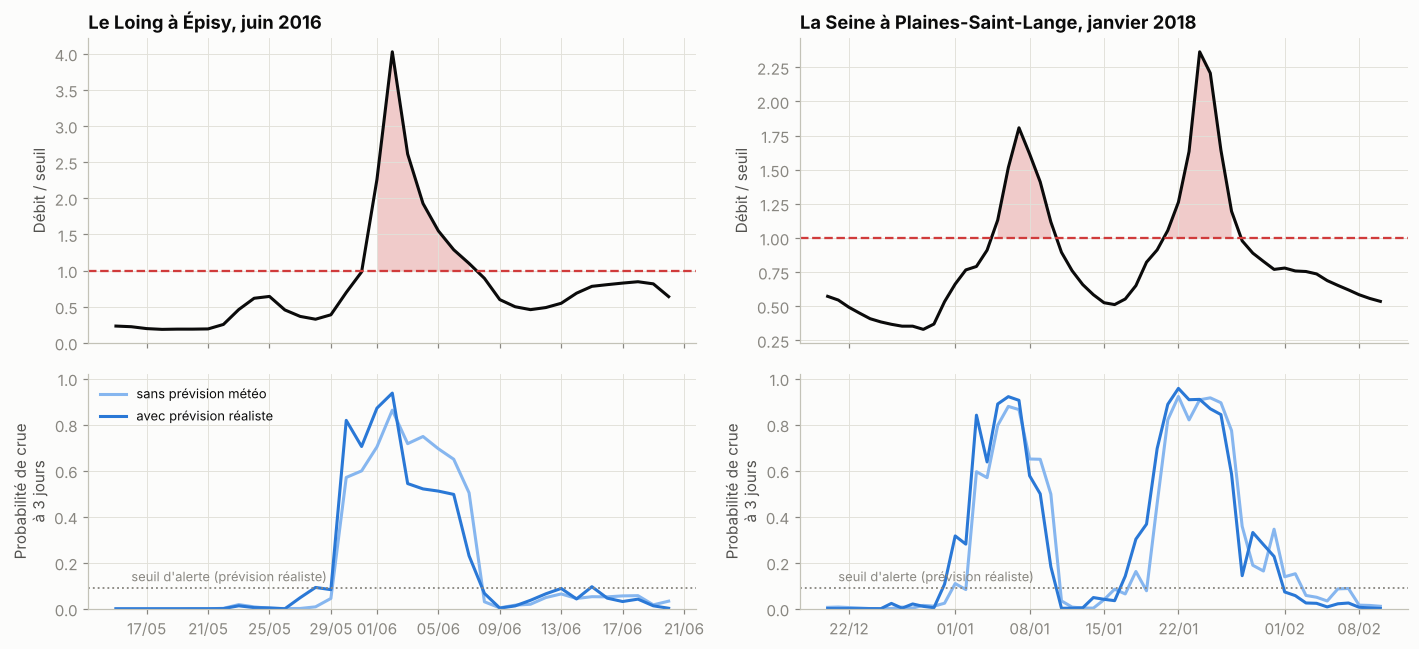

Loing - probabilité les 3 soirs avant le début de la crue : 29/05 8%, 30/05 82%, 31/05 70%
Seine - probabilité les 3 soirs avant le début de la crue : 18/01 30%, 19/01 37%, 20/01 70%


In [13]:
scenario = "Prévision réaliste"
t_real = tables[scenario][0]
te_real = t_real[t_real["periode"] == "test"].assign(p=predictions[(scenario, "XGBoost")],
                                                      p_sans=predictions[("Sans prévision météo", "XGBoost")])
seuil_real = modeles[(scenario, "XGBoost")][1]
seuil_sans = modeles[("Sans prévision météo", "XGBoost")][1]

def etude_de_cas(ax_q, ax_p, code_st, debut, fin, titre):
    g = te_real[(te_real["code"] == code_st) & te_real["date"].between(debut, fin)]
    ax_q.plot(g["date"], g["q_rel"], color=G.ENCRE, label="débit / seuil de crue")
    ax_q.axhline(1, color=G.CRUE, ls="--", lw=1.5)
    ax_q.fill_between(g["date"], 1, g["q_rel"], where=g["q_rel"] > 1, color=G.CRUE, alpha=0.25, lw=0)
    ax_q.set_ylabel("Débit / seuil")
    ax_q.set_title(titre)
    ax_p.plot(g["date"], g["p_sans"], color=G.COULEURS_SCENARIOS["Sans prévision météo"], label="sans prévision météo")
    ax_p.plot(g["date"], g["p"], color=G.COULEURS_SCENARIOS["Prévision réaliste"], label="avec prévision réaliste")
    ax_p.axhline(seuil_real, color=G.GRIS, ls=":", lw=1.2)
    ax_p.text(g["date"].iloc[1], seuil_real + 0.03, "seuil d'alerte (prévision réaliste)", color=G.GRIS, fontsize=8.5)
    ax_p.set_ylim(0, 1.02)
    ax_p.set_ylabel("Probabilité de crue\nà 3 jours")
    ax_p.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex="col", gridspec_kw={"height_ratios": [1.3, 1]})
etude_de_cas(axes[0, 0], axes[1, 0], "F439000101", "2016-05-15", "2016-06-20", "Le Loing à Épisy, juin 2016")
etude_de_cas(axes[0, 1], axes[1, 1], "H010002001", "2017-12-20", "2018-02-10", "La Seine à Plaines-Saint-Lange, janvier 2018")
axes[1, 0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG / "07_etudes_de_cas.png")
plt.show()

for code_st, d1 in [("F439000101", "2016-06-01"), ("H010002001", "2018-01-21")]:
    g = te_real[(te_real["code"] == code_st) & te_real["date"].between(pd.Timestamp(d1) - pd.Timedelta(days=3), pd.Timestamp(d1) - pd.Timedelta(days=1))]
    print(court[code_st], "- probabilité les 3 soirs avant le début de la crue :",
          ", ".join(f"{d:%d/%m} {p:.0%}" for d, p in zip(g["date"], g["p"])))

## 7. Qu'est-ce que le modèle regarde ?

On mesure l'importance de chaque **famille** de variables : on mélange au hasard toutes les variables d'une famille
sur la période de test et on regarde de combien la PR-AUC chute. Plus la chute est forte, plus le modèle
s'appuie sur cette information.

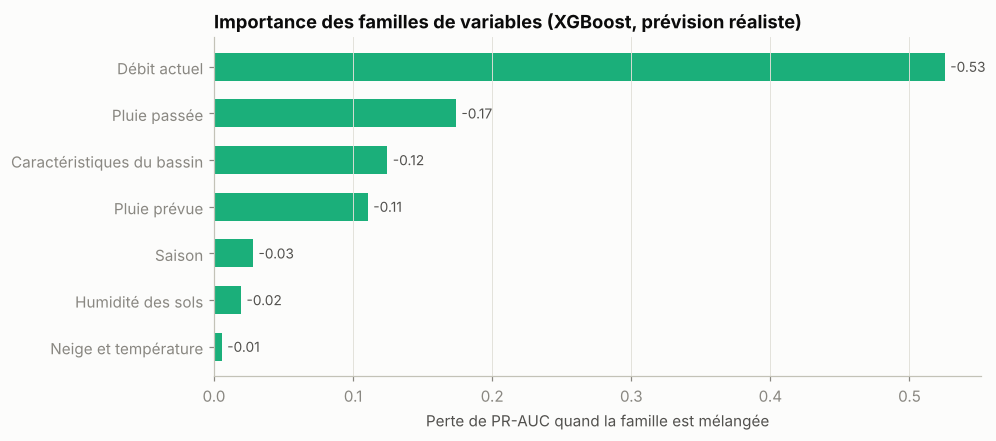

Débit actuel                  0.525
Pluie passée                  0.174
Caractéristiques du bassin    0.125
Pluie prévue                  0.111
Saison                        0.028
Humidité des sols             0.019
Neige et température          0.006
dtype: float64

In [14]:
t, cols = tables["Prévision réaliste"]
te = t[t["periode"] == "test"]
m, _ = modeles[("Prévision réaliste", "XGBoost")]
imp = importance_par_famille(m, te[cols], te[CIBLE], FAMILLES, n_rep=3)
imp.rename("Perte de PR-AUC").to_csv(RES / "importance_familles.csv", float_format="%.4f")

fig, ax = plt.subplots(figsize=(9, 4))
imp_tri = imp.sort_values()
ax.barh(imp_tri.index, imp_tri.values, color=G.COULEURS_MODELES["XGBoost"], height=0.6)
for y, v in enumerate(imp_tri.values):
    ax.text(v + 0.004, y, f"-{v:.2f}", va="center", fontsize=9, color=G.ENCRE_2)
ax.set_xlabel("Perte de PR-AUC quand la famille est mélangée")
ax.grid(axis="y", visible=False)
ax.set_title("Importance des familles de variables (XGBoost, prévision réaliste)")
fig.savefig(FIG / "08_importance_variables.png")
plt.show()
imp

Le **débit actuel** est de loin l'information la plus précieuse : une rivière déjà haute est à quelques millimètres
de pluie du débordement. Viennent ensuite la **pluie déjà tombée**, les **caractéristiques du bassin** (un petit bassin
pentu ne réagit pas comme la Meuse) et la **pluie prévue**. Le modèle a retrouvé seul la logique d'un hydrologue :
*état du bassin + pluie récente + pluie à venir = risque de crue*.

Attention à la lecture : l'humidité des sols et la neige semblent peu importantes, mais c'est en partie parce que
le débit actuel « contient » déjà cette information (un sol saturé fait monter la rivière). Les familles se recouvrent.

## 8. Une rivière jamais vue

Peut-on utiliser le modèle sur une rivière **sans historique** (un petit cours d'eau non équipé, par exemple) ?
On fait une validation « une station laissée de côté » : on entraîne XGBoost sur 18 bassins (1999-2010), puis on prédit
la 19e sur 2015-2018. On compare à la PR-AUC obtenue par le modèle qui connaissait cette station.

In [15]:
t, cols = tables["Prévision réaliste"]
m_ref, _ = modeles[("Prévision réaliste", "XGBoost")]
n_arbres = m_ref.best_iteration + 1
tr, va, te = decouper(t)
p_ref = pd.Series(predictions[("Prévision réaliste", "XGBoost")], index=te.index)

from sklearn.metrics import average_precision_score
lignes = []
for code_st in stations["code"]:
    test_st = te[te["code"] == code_st]
    if test_st[CIBLE].sum() < 3:       # trop peu de jours de crue pour mesurer quoi que ce soit
        continue
    m = xgboost(n_arbres=n_arbres)
    app = tr[tr["code"] != code_st]
    m.fit(app[cols], app[CIBLE])
    lignes.append({"code": code_st, "rivière": court[code_st], "jours de crue (test)": int(test_st[CIBLE].sum()),
                   "PR-AUC station connue": average_precision_score(test_st[CIBLE], p_ref.loc[test_st.index]),
                   "PR-AUC station inconnue": average_precision_score(test_st[CIBLE], proba(m, test_st[cols]))})
spatial = pd.DataFrame(lignes).set_index("code")
spatial.to_csv(RES / "generalisation_spatiale.csv", float_format="%.3f")
print(f"PR-AUC médiane : station connue {spatial['PR-AUC station connue'].median():.2f}, "
      f"station jamais vue {spatial['PR-AUC station inconnue'].median():.2f}")
spatial.sort_values("PR-AUC station inconnue", ascending=False)

PR-AUC médiane : station connue 0.61, station jamais vue 0.56


,rivière,jours de crue (test),PR-AUC station connue,PR-AUC station inconnue
code,,,,
H622101001,Aisne,19,0.933,0.925
F439000101,Loing,28,0.916,0.897
K134181001,Arroux,8,0.907,0.884
H120101001,Aube,40,0.825,0.795
B222001001,Meuse,11,0.838,0.791
H010002001,Seine,23,0.801,0.748
A605102001,Meurthe,8,0.722,0.740
X031001001,Durance,10,0.596,0.574
Y643401001,Esteron,10,0.624,0.546


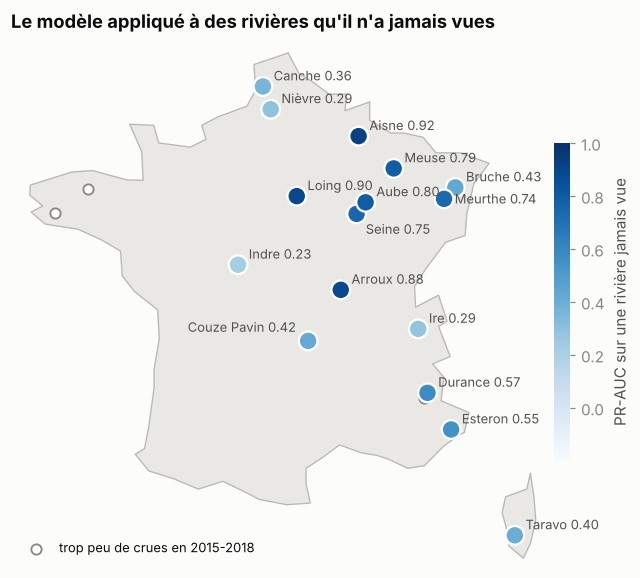

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 7.5))
fond_de_carte(ax)
st = stations.set_index("code")
autres = st.drop(spatial.index)
ax.scatter(autres["lon"], autres["lat"], s=45, facecolor="white", edgecolor=G.GRIS, linewidth=1.2, zorder=3,
           label="trop peu de crues en 2015-2018")
sc = ax.scatter(st.loc[spatial.index, "lon"], st.loc[spatial.index, "lat"], s=150,
                c=spatial["PR-AUC station inconnue"], cmap="Blues", vmin=-0.2, vmax=1,
                edgecolor="white", linewidth=1.5, zorder=4)
for code_st, r in spatial.iterrows():
    ax.annotate(f"{r['rivière']} {r['PR-AUC station inconnue']:.2f}", (st.loc[code_st, "lon"], st.loc[code_st, "lat"]),
                xytext=DECALAGE.get(code_st, (7, 4)), textcoords="offset points", fontsize=8.5,
                ha="right" if DECALAGE.get(code_st, (7, 4))[0] < 0 else "left", color=G.ENCRE_2, zorder=5)
cb = fig.colorbar(sc, ax=ax, shrink=0.5, pad=0.01, ticks=[0, 0.2, 0.4, 0.6, 0.8, 1])
cb.set_label("PR-AUC sur une rivière jamais vue")
cb.outline.set_visible(False)
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Le modèle appliqué à des rivières qu'il n'a jamais vues")
fig.savefig(FIG / "09_carte_generalisation.png")
plt.show()

## 9. Conclusion

In [17]:
r = res.set_index(["Scénario", "Modèle"])
xs, xr, xp = (r.loc[(s, "XGBoost")] for s in G.COULEURS_SCENARIOS)
naif = r.loc[("Sans prévision météo", "Règle naïve")]
ep_r = par_episode.loc["Prévision réaliste"]
print(f"""Résumé automatique (période de test 2015-2018, jamais vue pendant l'apprentissage)

- Sans prévision météo, XGBoost atteint une PR-AUC de {xs['PR-AUC']:.2f}, contre {naif['PR-AUC']:.2f} pour la règle naïve
  (et environ {y_test.mean():.2f} pour un tirage au hasard).
- Avec une prévision de pluie réaliste (très imparfaite), la PR-AUC monte à {xr['PR-AUC']:.2f} ;
  avec une prévision parfaite, elle atteindrait {xp['PR-AUC']:.2f}.
- Par épisode : {ep_r["Annoncés à l'avance"]:.0%} des {ep_r["Épisodes de crue"]:.0f} crues sont annoncées à l'avance,
  {ep_r["Avance moyenne (jours)"]:.1f} jours avant en moyenne, pour environ {ep_r["Alertes par station et par an"]:.0f} jours d'alerte par station et par an.
- Sur une rivière jamais vue, la PR-AUC médiane est de {spatial['PR-AUC station inconnue'].median():.2f}
  (contre {spatial['PR-AUC station connue'].median():.2f} quand la station est connue).
- Information la plus utile : « {imp.index[0]} », puis « {imp.index[1]} ».""")

Résumé automatique (période de test 2015-2018, jamais vue pendant l'apprentissage)

- Sans prévision météo, XGBoost atteint une PR-AUC de 0.54, contre 0.32 pour la règle naïve
  (et environ 0.01 pour un tirage au hasard).
- Avec une prévision de pluie réaliste (très imparfaite), la PR-AUC monte à 0.60 ;
  avec une prévision parfaite, elle atteindrait 0.68.
- Par épisode : 79% des 61 crues sont annoncées à l'avance,
  2.4 jours avant en moyenne, pour environ 6 jours d'alerte par station et par an.
- Sur une rivière jamais vue, la PR-AUC médiane est de 0.56
  (contre 0.61 quand la station est connue).
- Information la plus utile : « Débit actuel », puis « Pluie passée ».


**Limites et pistes**
- **Pas de données de dégâts** : « en crue » veut dire ici « au-dessus de la crue biennale ». Une vraie inondation
  dépend aussi des digues, de l'urbanisation et de la hauteur d'eau locale. Croiser avec la base des arrêtés
  de catastrophe naturelle (GASPAR) permettrait de prédire directement les communes sinistrées.
- **Pas de vraie prévision météo** : le scénario réaliste dégrade la pluie observée. Utiliser les prévisions archivées
  (modèle AROME de Météo-France, ou ECMWF) donnerait une mesure honnête du gain.
- **Pas de temps journalier** : les petits bassins de montagne et méditerranéens réagissent en quelques heures.
  Des données horaires (Hub'Eau, API hydrométrie) amélioreraient la détection des crues éclair.
- **19 bassins** : la base CAMELS-FR complète en compte plus de 650. L'étendre rendrait la généralisation
  aux rivières non jaugées bien plus solide.
- **Calibration** : les probabilités pourraient être recalibrées (régression isotonique) pour qu'une alerte à 30 %
  corresponde vraiment à 30 % de crues observées.